# Onset of steroid activity in the ageing thymus: AKR1C enzymes, AR / NR3C1 activity and the cortical programme

**Question.** When do androgen-**activating** (`AKR1C3`) and androgen-**inactivating**
(`AKR1C2 + AKR1C1`) enzyme expression and **AR / NR3C1 regulon activity** rise, relative to adrenarche
(6–8 y) and puberty (8–14 y)?

* **(a)** in **TEC, Fb, EC, Mural** and **T** cells (`taa_l1`);
* **(b)** in **cTEC, mcTEC** and **mTEC** (`taa_l2_v2`), together with the **cortical cTEC programme**.

Every quantity stays **in its own unit**, on its own row of panels. The x axis is shared down a column,
so timing lines up across rows:

| row | trace | unit |
|---|---|---|
| 1 | `AKR1C3` (activation: A4 → T, 11KA4 → 11KT); `AKR1C2+AKR1C1` (inactivation: DHT → 3α-diol; the two near-identical paralogues summed) | log1p CP10K |
| 2 | `AR`, `NR3C1`: CollecTRI regulon activity | z against the cell type's expression-matched null |
| 3 (b only) | `core cTEC` (`FOXN1, PSMB11, PRSS16, CCL25, TBATA, DLL4, LY75`) and `FOXN1 targets` (Žuklys et al. 2016, 447 human orthologs), each scored as a regulon | z, scored exactly as row 2 |

**Design.**

* Donors: pseudobulks with **≥ 20 cells** (20–99 drawn hollow); donors **A66** and **A74** removed (as in
  notebook 06); **strong outliers removed** by a stated rule (section 5).
* Activity z: the value of notebook 06. A donor's AR / NR3C1 z is the same number in both notebooks.
* Age trends: **LOWESS on age in years** (linear), with a 95 % bootstrap band (donors resampled), fitted
  separately over **all ages** and over donors **up to 20 y** (the zoom on the window that matters).
  The fit is drawn **through** the ages with no donor; those ages are hatched. Grey bands: adrenarche
  6–8 y, puberty 8–14 y.
* Sequencing depth: the figures are drawn twice, as measured (section 6) and with **AR and NR3C1
  activity corrected for depth** (section 8: notebook 06's covariates, `log10` library size and `log10`
  cells per pseudobulk, with the depth slope estimated within age groups so it cannot remove the age
  trend). Enzyme expression and the cortical scores are not corrected.

**What this can and cannot answer.** The epithelial panels have no donors between ~1.2 and 6 y or
between ~11 and 19 y. Onset can be **bracketed** by the donors on either side of a gap, but not
**located** inside it. Study is partly confounded with age (the older children come from one study).
Traces that move together are not thereby coupled: everything that changes with age correlates across
donors.

| section | |
|---|---|
| 1 | set-up |
| 2 | data: regulons and gene sets, donor pseudobulks |
| 3 | activity z for every donor (notebook 01's functions, as in notebook 06) |
| 4 | enzyme expression and its detection floor |
| 5 | strong outliers |
| 6 | **age-trend figures** (`taa_l1`; `taa_l2_v2`) × (all ages; up to 20 y) |
| 7 | the numbers: medians per age group |
| 8 | **the same figures with AR / NR3C1 activity corrected for sequencing depth**; what it changes |
| 9 | summary; 10 outputs |


## 1. Set-up


In [1]:
import os, sys, time, warnings, logging
from collections import OrderedDict

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import hdf5plugin            # registers the HDF5 compression filters the aggregates are written with
import anndata as ad
import decoupler as dc
from scipy.stats import mannwhitneyu, spearmanr
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rcParams, font_manager
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)
print(f'python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | '
      f'scipy {scipy.__version__} | anndata {ad.__version__} | decoupler {dc.__version__} | '
      f'matplotlib {matplotlib.__version__}')


python 3.12.0 | numpy 2.2.4 | pandas 2.2.3 | scipy 1.15.2 | anndata 0.11.4 | decoupler 2.1.1 | matplotlib 3.10.1


In [2]:
# ------------------------------------------------------------------ paths (edit for your setup)
DEA_DIR = '/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/data/analyses/dea'
# donor x cell-type raw-count pseudobulks, one per annotation level (.h5ad files despite the suffix)
AGG_PATHS = {lv: f'{DEA_DIR}/thyAgeing_all_v6_2026-05-01_{lv}_aggAdata.zarr' for lv in ('taa_l1', 'taa_l2_v2')}
HERE = os.environ.get('NB_OUT_DIR', os.getcwd())          # this folder: data/, results/, figures/
DATA_DIR, RESULTS, FIGURES = f'{HERE}/data', f'{HERE}/results', f'{HERE}/figures'
for d in (RESULTS, FIGURES):
    os.makedirs(d, exist_ok=True)

PREFIX = 'thyAgeing_steroidOnset'
FOXN1_CSV = f'{DATA_DIR}/FOXN1_targets_human.csv'     # Zuklys 2016 targets, mapped to human (section 2)

# ------------------------------------------------------------------ what is analysed
POPS = OrderedDict([('TEC',   ('taa_l1', 'TEC')),       # display name -> (annotation level, cell type)
                    ('Fb',    ('taa_l1', 'Fb')),
                    ('EC',    ('taa_l1', 'EC')),
                    ('Mural', ('taa_l1', 'Mural')),
                    ('T',     ('taa_l1', 'T')),
                    ('cTEC',  ('taa_l2_v2', 'cTEC')),
                    ('mcTEC', ('taa_l2_v2', 'mcTEC')),
                    ('mTEC',  ('taa_l2_v2', 'mTEC'))])
CORTICAL_LEVELS = {'taa_l2_v2'}                         # the cortical programme is drawn at these levels
RECEPTORS = ['AR', 'NR3C1']
CORE_CTEC = ['FOXN1', 'PSMB11', 'PRSS16', 'CCL25', 'TBATA', 'DLL4', 'LY75']
AGE_GROUPS, SEXES = ['infant', 'paed', 'adult'], ['F', 'M']

# ------------------------------------------------------------------ donors
MIN_CELLS  = 20       # a donor x cell-type pseudobulk is analysed with >= MIN_CELLS cells ...
FULL_CELLS = 100      # ... and drawn hollow below FULL_CELLS
EXCLUDE_DONORS = {'A66': 'obese donor; excluded from the adult sex-DE of the atlas',
                  'A74': 'excluded from a variant of the adult sex-DE of the atlas'}

# ------------------------------------------------------------------ enzyme detection floor
# a trace is "detected" with counts > 0 in >= 8 donors, >= 20 counts in >= 3 donors and >= 0.1 CP10K in
# >= 3 donors; otherwise it is drawn faded and labelled. The CP10K term matters for big pseudobulks: T cells
# (~8,000 per donor) reach 20 counts of a gene expressed in 0.1 % of them.
DET_MIN_NONZERO, DET_MIN_COUNTS, DET_MIN_DONORS, DET_MIN_CP10K = 8, 20, 3, 0.1

# ------------------------------------------------------------------ strong outliers (section 5)
OUTLIER_Z = 4.0              # >= 4 SD from the other donors of the same age group (leave-one-out) ...
OUTLIER_MIN_OTHERS = 4       # ... in an age group with >= 4 other donors, beyond every other donor of the
                             # panel, and removed only when its pseudobulk has < FULL_CELLS cells

# ------------------------------------------------------------------ age trends
WINDOWS = OrderedDict([('allAges', np.inf), ('upto20y', 20.0)])
WINDOW_LABEL = {'allAges': 'all ages', 'upto20y': 'donors up to 20 y'}
LOWESS_FRAC, N_BOOT = 0.75, 1000
ADRENARCHE, PUBERTY = (6.0, 8.0), (8.0, 14.0)

# ------------------------------------------------------------------ depth correction (section 8)
DEPTH_TRACES = ['AR', 'NR3C1']              # corrected for depth; enzyme expression and cortical scores are not
DEPTH_COVS = ['log10_lib', 'log10_cells']   # notebook 06's depth covariates

# ------------------------------------------------------------------ scoring (notebook 01's parameters)
UNIVERSE_MIN_COUNTS = 10    # a gene is scored in a cell type with >= 10 counts summed over its pseudobulks
TMIN   = 5                  # a regulon is scored with >= TMIN targets in the gene universe
N_BINS = 20                 # expression bins of the null
N_PERM = int(os.environ.get('NB_N_PERM', 1000))           # permutations per donor (NB_N_PERM=20: smoke test)
SEED   = 0
FORCE_RESCORE = os.environ.get('NB_FORCE_RESCORE', '0') == '1'

SCORES_CSV = f'{RESULTS}/{PREFIX}_activity_perDonor.csv'   # cache: reused while the analysis set is unchanged

PROGRESS = f'{RESULTS}/{PREFIX}_progress.log'


def log_step(msg):
    """Print a time-stamped milestone and append it to the progress log (readable while the notebook runs)."""
    line = f'[{time.strftime("%Y-%m-%d %H:%M:%S")}] {msg}'
    with open(PROGRESS, 'a') as fh:
        fh.write(line + '\n')
    print(line, flush=True)


log_step(f'=== notebook start | {len(POPS)} populations | {N_PERM} permutations | outputs in {HERE}')


[2026-11-23 00:24:14] === notebook start | 8 populations | 1000 permutations | outputs in /nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/notebooks/hormone2cell/_builders/../final_versions/github


In [3]:
# ------------------------------------------------------------------ figure style (notebook 01's)
logging.getLogger('fontTools').setLevel(logging.WARNING)      # PDF font subsetting is chatty at INFO
logging.getLogger('matplotlib').setLevel(logging.WARNING)
try:                                                          # Arial if available (Nature house font)
    font_manager.fontManager.addfont('/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf')
except Exception:
    pass
rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'pdf.fonttype': 42, 'ps.fonttype': 42,                   # text stays editable in Illustrator
    'font.size': 7, 'axes.titlesize': 7, 'axes.labelsize': 7,
    'xtick.labelsize': 6, 'ytick.labelsize': 6, 'legend.fontsize': 6, 'figure.titlesize': 8,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'xtick.major.size': 2, 'ytick.major.size': 2, 'xtick.major.pad': 1.5, 'ytick.major.pad': 1.5,
    'savefig.dpi': 300, 'savefig.bbox': 'standard',          # 'standard': the PDF keeps the size in mm below
    'savefig.transparent': False, 'figure.dpi': 110,
})
MM = 1 / 25.4                                                # inches per mm
NATURE_W = {'single': 89.0, 'two-thirds': 120.0, 'double': 183.0}   # Nature figure widths, mm

# one colour + marker per steroid receptor (identical across all notebooks of the release)
RECEPTOR_STYLE = {'AR':    ('#d95f02', 'o'),
                  'NR3C1': ('#1b9e77', '*'),
                  'PGR':   ('#7570b3', 'D'),
                  'ESR1':  ('#b2182b', 's'),
                  'ESR2':  ('#56B4E9', '^')}


def mm_fig(width_mm, height_mm):
    """A figure of exactly this size in millimetres; constrained layout keeps labels inside it."""
    return plt.figure(figsize=(width_mm * MM, height_mm * MM), layout='constrained')


def save_fig(fig, name):
    """Save `FIGURES/<name>.pdf` at the figure's size in mm, and report it."""
    path = f'{FIGURES}/{name}.pdf'
    fig.savefig(path)
    w, h = np.asarray(fig.get_size_inches()) * 25.4
    print(f'saved {os.path.basename(path)}  ({w:.0f} x {h:.0f} mm)')
    return path


# one entry per trace: colour, marker, line style. Enzymes: the IBM colour-blind-safe magenta / blue of
# the earlier onset notebooks; receptors: the release colours above; cortical scores: neutral ink.
TRACES = OrderedDict([
    ('AKR1C3',        dict(kind='enzyme', genes=['AKR1C3'], color='#DC267F', marker='o', ls='-')),
    ('AKR1C2+AKR1C1', dict(kind='enzyme', genes=['AKR1C2', 'AKR1C1'], color='#648FFF', marker='s', ls='-')),
    ('AR',            dict(kind='activity', source='AR', color=RECEPTOR_STYLE['AR'][0],
                           marker=RECEPTOR_STYLE['AR'][1], ls='-')),
    ('NR3C1',         dict(kind='activity', source='NR3C1', color=RECEPTOR_STYLE['NR3C1'][0],
                           marker=RECEPTOR_STYLE['NR3C1'][1], ls='-')),
    ('core cTEC',     dict(kind='activity', source='core_cTEC', color='#252525', marker='D', ls=(0, (4.0, 1.6)))),
    ('FOXN1 targets', dict(kind='activity', source='FOXN1_targets', color='#7a7a7a', marker='v',
                           ls=(0, (1.2, 1.2)))),
])
ROWS = [('enzymes', ['AKR1C3', 'AKR1C2+AKR1C1'], 'expression\n(log1p CP10K)'),
        ('receptors', ['AR', 'NR3C1'], 'regulon activity\n(z)'),
        ('cortical', ['core cTEC', 'FOXN1 targets'], 'cortical programme\n(z)')]


def rows_for(level):
    return [r for r in ROWS if r[0] != 'cortical' or level in CORTICAL_LEVELS]


def traces_for(pop):
    return [t for _, ts, _ in rows_for(POPS[pop][0]) for t in ts]


## 2. Data

**2.1 Regulons and gene sets.** The CollecTRI AR and NR3C1 regulons (signed weights), and the two cortical
gene sets as regulons with every weight +1:

* `core cTEC`: the project's curated core cortical set used in the TEC age-DE figures;
* `FOXN1 targets`: Supplementary Table 2 of Žuklys et al. 2016 (*Nat Immunol* 17:1206), the
  "high-confidence" mouse Foxn1 targets. These genes have a Foxn1 ChIP-seq peak within −5 kb / +100 b of
  the TSS **and** fall when Foxn1 is lost in postnatal cTEC (449 rows). They are mapped to human in
  `data/FOXN1_targets_human.csv`. Each 2016 symbol is first updated with MGI's withdrawn-symbol report
  (`Aes` → `Tle5`, `Sept8` → `Septin8`, …), then taken through a strict 1:1 MGI homology class, or else
  the same-name human member of the class. The `mapping` column records the rule for every gene.

Six of the seven core cTEC genes are Foxn1 targets, so the two cortical scores are **not
independent**. The core set is the canonical-function subset of the broader Foxn1 programme.


In [4]:
NET_CSV = f'{DATA_DIR}/CollecTRI_regulons_human.csv'
if os.path.exists(NET_CSV):
    collectri = pd.read_csv(NET_CSV)
    print('CollecTRI read from', NET_CSV)
else:
    collectri = dc.op.collectri(organism='human')[['source', 'target', 'weight']]
    collectri.to_csv(NET_CSV, index=False)
    print('CollecTRI downloaded through decoupler and cached to', NET_CSV)
collectri = collectri.drop_duplicates(['source', 'target']).reset_index(drop=True)
print(f'{collectri["source"].nunique():,} regulons | {len(collectri):,} TF-target edges')

FOXN1 = pd.read_csv(FOXN1_CSV, dtype=str)
FOXN1_TARGETS = list(dict.fromkeys(FOXN1['human_symbol'].dropna()))
print(f'Foxn1 targets: {len(FOXN1)} mouse genes -> {len(FOXN1_TARGETS)} human genes')
display(FOXN1.groupby(['symbol_status', 'mapping'], dropna=False).size().rename('genes').to_frame())
GENE_SETS = {'core_cTEC': CORE_CTEC, 'FOXN1_targets': FOXN1_TARGETS}
print('core cTEC genes that are also Foxn1 targets:', [g for g in CORE_CTEC if g in set(FOXN1_TARGETS)])

net = pd.concat([collectri[collectri['source'].isin(RECEPTORS)]]
                + [pd.DataFrame({'source': s, 'target': g, 'weight': 1.0}) for s, g in GENE_SETS.items()],
                ignore_index=True).drop_duplicates(['source', 'target']).reset_index(drop=True)
display(net.groupby('source', sort=False)['weight'].agg(targets='size', activating=lambda w: int((w > 0).sum()),
                                                        repressing=lambda w: int((w < 0).sum())).T)


CollecTRI read from /nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/notebooks/hormone2cell/_builders/../final_versions/github/data/CollecTRI_regulons_human.csv
1,185 regulons | 42,990 TF-target edges
Foxn1 targets: 449 mouse genes -> 447 human genes


genes
symbol_status mapping                               
current       1:1                                408
              no human ortholog in MGI             2
              same-name member of a 1:2 class      3
              same-name member of a 1:3 class      2
renamed       1:1                                 33
              same-name member of a 1:7 class      1

core cTEC genes that are also Foxn1 targets: ['PSMB11', 'PRSS16', 'CCL25', 'TBATA', 'DLL4', 'LY75']


source,AR,NR3C1,core_cTEC,FOXN1_targets
targets,514,292,7,447
activating,470,226,7,447
repressing,44,66,0,0


**2.2 Donor pseudobulks.** One aggregate per annotation level, one row per donor × cell type (raw
summed counts, pseudobulks of ≥ 10 cells). These are the inputs of the atlas DESeq2 runs. Age is checked
against its own string, the gene universe of each population is fixed from all its pseudobulks, and then
the analysis set is selected: without A66 and A74, with ≥ `MIN_CELLS` cells.


In [5]:
def load_aggregate(level):
    """One annotation level's raw-count pseudobulks (one row per donor x cell type with >= 10 cells):
    the count matrix, the gene symbols and one metadata row per pseudobulk."""
    pb = ad.read_h5ad(AGG_PATHS[level])
    X = sp.csr_matrix(pb.X)
    assert np.array_equal(X.data, np.rint(X.data)), f'{level}: X is not raw counts'
    genes = pd.Index(pb.var_names.astype(str))
    assert genes.is_unique, f'{level}: duplicated gene symbols'
    o = pb.obs
    meta = pd.DataFrame({'level': level, 'row': np.arange(pb.n_obs),
                         'cell_type': o[level].astype(str).to_numpy(),
                         **{c: o[c].astype(str).to_numpy() for c in ('donor', 'sex', 'age_group', 'age', 'study')},
                         'age_months': o['age_months'].astype(float).to_numpy(),
                         'n_cells': o['n_cells'].astype(float).to_numpy(),
                         'lib_size': np.asarray(X.sum(axis=1)).ravel().astype(float)})
    print(f'{level}: {pb.n_obs} pseudobulks x {pb.n_vars:,} genes | {o["donor"].nunique()} donors')
    return X, genes, meta


LEVELS = list(dict.fromkeys(lv for lv, _ in POPS.values()))
XS, GENES, parts = {}, {}, []
for lv in LEVELS:
    XS[lv], GENES[lv], m = load_aggregate(lv)
    parts.append(m)
key2pop = {v: k for k, v in POPS.items()}
ALL = pd.concat(parts, ignore_index=True)
ALL['population'] = [key2pop.get(k) for k in zip(ALL['level'], ALL['cell_type'])]
absent = [p for p in POPS if p not in set(ALL['population'])]
assert not absent, f'{absent} absent from the aggregates'
DON = ALL[ALL['population'].notna()].reset_index(drop=True)

# metadata checks
assert set(DON['sex']) <= set(SEXES), f'unexpected sex labels: {sorted(set(DON["sex"]))}'
assert set(DON['age_group']) <= set(AGE_GROUPS), f'unexpected age groups: {sorted(set(DON["age_group"]))}'
assert not DON.duplicated(['population', 'donor']).any(), 'a donor has two pseudobulks of one population'
same = DON.groupby('donor')[['sex', 'age_group', 'age', 'study']].nunique()
assert (same == 1).all().all(), 'donor metadata differ between the annotation levels'
# age: `age_num` alone is unit-less in this atlas; the age string ("7d", "1.6m", "6y") must agree with age_months
UNIT_MONTHS = {'d': 12 / 365.25, 'm': 1.0, 'y': 12.0}
parsed = DON['age'].str.extract(r'^\s*([\d.]+)\s*([dmy])\s*$')
assert parsed.notna().all().all(), f'unparsed age strings: {sorted(set(DON.loc[parsed[0].isna(), "age"]))}'
max_diff = float((parsed[0].astype(float) * parsed[1].map(UNIT_MONTHS) - DON['age_months']).abs().max())
assert max_diff <= 0.51, f'age string and age_months disagree by {max_diff:.2f} months'
DON['age_years'] = DON['age_months'] / 12
print(f'age string vs age_months: max |diff| {max_diff:.2f} months')

# gene universe per population: >= UNIVERSE_MIN_COUNTS counts summed over ALL its pseudobulks. This is
# DESeq2's filter, so the universe is exactly the set of genes tested in the atlas age-DE (notebooks 01-04).
UNIVERSE = {}
for pop, (lv, _) in POPS.items():
    rows = DON.loc[DON['population'] == pop, 'row'].to_numpy()
    total = np.asarray(XS[lv][rows].sum(axis=0)).ravel()
    UNIVERSE[pop] = np.sort(GENES[lv][total >= UNIVERSE_MIN_COUNTS].to_numpy())

# the analysis set
DON['excluded_donor'] = DON['donor'].isin(list(EXCLUDE_DONORS))
DON['analysed'] = ~DON['excluded_donor'] & (DON['n_cells'] >= MIN_CELLS)
DON['hollow'] = DON['n_cells'] < FULL_CELLS
DON['log10_lib'] = np.log10(DON['lib_size'])
DON['log10_cells'] = np.log10(DON['n_cells'])
META = ['population', 'level', 'cell_type', 'donor', 'sex', 'age_group', 'age', 'age_years', 'study',
        'n_cells', 'lib_size', 'log10_lib', 'log10_cells', 'hollow']
print('Removed donors:')
for dn, why in EXCLUDE_DONORS.items():
    r = DON[DON['donor'] == dn]
    print(f'  {dn} ({why}): ' + (', '.join(f'{p} ({int(n)} cells)' for p, n in zip(r['population'], r['n_cells']))
                                 if len(r) else 'no pseudobulk in these populations'))
log_step('aggregates loaded')


taa_l1: 395 pseudobulks x 35,530 genes | 58 donors


taa_l2_v2: 904 pseudobulks x 35,530 genes | 58 donors
age string vs age_months: max |diff| 0.50 months
Removed donors:
  A66 (obese donor; excluded from the adult sex-DE of the atlas): EC (5241 cells), Fb (1384 cells), Mural (842 cells), TEC (881 cells), T (5947 cells), mTEC (504 cells), mcTEC (353 cells)
  A74 (excluded from a variant of the adult sex-DE of the atlas): EC (467 cells), Fb (1159 cells), Mural (201 cells), TEC (303 cells), T (9145 cells), cTEC (10 cells), mTEC (119 cells), mcTEC (169 cells)
[2026-11-23 00:24:15] aggregates loaded


In [6]:
def age_mix(d):
    c = d['age_group'].value_counts()
    return '/'.join(str(int(c.get(g, 0))) for g in AGE_GROUPS)


A = DON[DON['analysed']]
summary = pd.DataFrame({
    'level': [POPS[p][0] for p in POPS],
    'donors': [int((A['population'] == p).sum()) for p in POPS],
    'infant/paed/adult': [age_mix(A[A['population'] == p]) for p in POPS],
    'hollow (20-99 cells)': [int((A['hollow'] & (A['population'] == p)).sum()) for p in POPS],
    'median cells': [A.loc[A['population'] == p, 'n_cells'].median() for p in POPS],
    'ages 1.5-18 y': [', '.join(f'{a:g}' for a in sorted(A.loc[(A['population'] == p) & A['age_years'].between(1.5, 18),
                                                                 'age_years'].round(1))) for p in POPS],
    'genes in the universe': [len(UNIVERSE[p]) for p in POPS]}, index=list(POPS))
display(summary)


,level,donors,infant/paed/adult,hollow (20-99 cells),median cells,ages 1.5-18 y,genes in the universe
TEC,taa_l1,33,14/7/12,5,1278.0,"6, 8, 8, 9, 10, 10, 11",28819
Fb,taa_l1,29,12/5/12,7,586.0,"6, 8, 9, 10, 11",23646
EC,taa_l1,27,12/4/11,7,502.0,"6, 8, 9, 11",22387
Mural,taa_l1,24,8/5/11,6,388.0,"6, 8, 9, 10, 11",18917
T,taa_l1,55,33/10/12,2,8207.0,"2, 2.5, 2.5, 2.8, 5, 6, 8, 8, 9, 10, 10, 11, 1...",26193
cTEC,taa_l2_v2,25,14/5/6,6,206.0,"6, 8, 9, 10, 11",20012
mcTEC,taa_l2_v2,26,11/5/10,7,356.0,"6, 8, 9, 10, 11",21699
mTEC,taa_l2_v2,30,14/5/11,2,677.0,"6, 8, 9, 10, 11",27510


## 3. Activity z for every donor


**How a donor is scored.** For one population and its analysed donors:

1. **Gene universe:** the genes with ≥ 10 counts summed over the population's pseudobulks (DESeq2's
   filter, so these are the genes tested in the atlas age-DE). The universe is the same for every donor.
2. **Expression:** CP10K from the raw pseudobulk counts (library size over all genes), then `log1p`.
3. **`score`:** the univariate linear model (ULM, as in `decoupler`) of the donor's profile on the
   regulon's signed weights. This is the t-value of their correlation over the universe.
4. **`z`:** the same score against an **expression-matched null.** The donor's profile is permuted
   `N_PERM` times *within* 20 expression bins and rescored, so every gene trades values only with genes
   of similar expression; `z = (score − null mean) / null SD`.

**Why the null is needed.** On an expression profile the ULM asks whether a regulon's targets are more
expressed than the average gene. Literature-curated targets are, whatever the regulator is doing
(CollecTRI AR targets sit around the 70th–80th expression percentile). The null asks instead whether the
targets sit above *genes of the same expression level*, which removes that bias. The bins come from the
population's **pooled** expression, so they are the same genes in every donor. Binning on the donor's
own values would hand every gene back about its own value. Every donor is shuffled with the same
permutations (`permutation_null` reseeds each call), so donors differ by less Monte-Carlo noise. It is
the same null as drawing each "decoy" target from the expression bin of the real target it replaces.

The scoring functions are notebook 01's, copied unchanged. There they scored a vector of DESeq2 Wald
statistics; here they score a donor's profile.

The same procedure, with the same functions, gene universe, donors and seed as notebook 06, so the
AR and NR3C1 z of a donor are identical in the two notebooks. The cortical gene sets are scored in exactly
the same way (all weights +1), so their z asks whether the set's genes sit above genes of similar
expression in that donor. The scores are cached in `results/` (`NB_FORCE_RESCORE=1` recomputes them).


In [7]:
# ------------------------------------------------------------------ notebook 01's scoring functions
# copied verbatim from the release cells of notebook 01 (20_scoring, 21_check); only the input differs:
# there a vector of DESeq2 Wald statistics, here a donor's expression profile.
EPS = 2.2e-16                     # decoupler's guard in its t-value


def build_adjacency(universe, net, tmin=TMIN):
    """Genes x regulons weight matrix over `universe` (sorted gene symbols), column-standardised.
    Regulons with fewer than `tmin` targets in the universe are dropped (decoupler's `tmin`)."""
    gi = pd.Series(np.arange(len(universe)), index=universe)
    sub = net[net['target'].isin(gi.index)]
    n_tg = sub.groupby('source')['target'].size()
    srcs = sorted(n_tg.index[n_tg >= tmin])
    sub = sub[sub['source'].isin(set(srcs))]
    si = pd.Series(np.arange(len(srcs)), index=srcs)
    A = np.zeros((len(universe), len(srcs)), dtype=np.float64)
    A[gi[sub['target']].to_numpy(), si[sub['source']].to_numpy()] = sub['weight'].to_numpy()
    A_std = (A - A.mean(axis=0)) / A.std(axis=0, ddof=1)
    return srcs, A_std, n_tg.reindex(srcs).to_numpy()


def ulm(Y, A_std):
    """decoupler's univariate linear model written out: every row of Y (a vector over the universe)
    against every column of A_std. Returns (t, r) with t = r*sqrt(df/(1-r^2)), df = n_genes - 2."""
    Y = np.asarray(Y, dtype=np.float64)          # float64: float32 accumulation drifts ~2e-4
    n = Y.shape[1]
    Y_std = (Y - Y.mean(axis=1, keepdims=True)) / Y.std(axis=1, ddof=1, keepdims=True)
    r = (Y_std @ A_std) / (n - 1)
    return r * np.sqrt((n - 2) / ((1.0 - r + EPS) * (1.0 + r + EPS))), r


def abundance_bins(basemean, n_bins=N_BINS):
    """Quantile bin of baseMean per gene (ranked first so ties split deterministically)."""
    return pd.qcut(pd.Series(basemean).rank(method='first'), n_bins, labels=False).to_numpy()


def permute_within_bins(v, bins, rng, k):
    """k permutations of `v` (k x n_genes, in the ORIGINAL gene order) in which every gene receives
    the value of a gene from its own abundance bin.

    Genes are sorted by bin so each bin is a contiguous block; sorting `bin + U(0,1)` shuffles inside
    the blocks without mixing them; the result is then written back to the original gene order, which
    is the order of the rows of the adjacency it is scored against.
    """
    order = np.argsort(bins, kind='stable')
    g = bins[order].astype(np.float64)
    keys = g[None, :] + rng.random((k, g.size))
    shuffled = np.asarray(v, dtype=np.float64)[order][np.argsort(keys, axis=1, kind='stable')]
    out = np.empty_like(shuffled)
    out[:, order] = shuffled
    return out


def permutation_null(y, basemean, A_std, n_perm=N_PERM, seed=SEED, batch=200):
    """n_perm x n_regulons scores of `y` permuted WITHIN abundance bins (a regulon keeps its
    targets; the statistics are shuffled among genes of similar expression level)."""
    bins = abundance_bins(basemean)
    rng = np.random.default_rng(seed)
    out = np.empty((n_perm, A_std.shape[1]), dtype=np.float32)
    for start in range(0, n_perm, batch):
        k = min(batch, n_perm - start)
        out[start:start + k] = ulm(permute_within_bins(y, bins, rng, k), A_std)[0]
    return out


def check_permutation(bins, n=5):
    """The null must keep every gene inside its own abundance bin: permuting the bin labels
    themselves has to hand every gene back its own label, and each row must be a permutation."""
    rng = np.random.default_rng(SEED)
    P = permute_within_bins(bins, bins, rng, n)
    assert np.array_equal(P, np.tile(bins.astype(np.float64), (n, 1))), 'a value crossed bins'
    v = np.arange(bins.size, dtype=np.float64)
    Q = permute_within_bins(v, bins, rng, n)
    assert all(np.array_equal(np.sort(q), v) for q in Q), 'not a permutation'
    moved = (Q != v).mean()
    print(f'permutation null: every gene keeps its abundance bin ({bins.size:,} genes, '
          f'{len(np.unique(bins))} bins); {moved:.1%} of genes change value per permutation')


In [8]:
def population_matrix(pop):
    """One population: its analysed donors (rows of DON, sorted by donor), their raw counts over all genes,
    the gene universe, log1p CP10K over the universe (library size = all genes) and the pooled CP10K of
    every universe gene (all analysed donors' counts summed -- the analogue of DESeq2's baseMean)."""
    lv = POPS[pop][0]
    d = DON[(DON['population'] == pop) & DON['analysed']].sort_values('donor').reset_index(drop=True)
    C = XS[lv][d['row'].to_numpy()].toarray().astype(np.float64)
    universe = UNIVERSE[pop]
    gidx = GENES[lv].get_indexer(universe)
    L = np.log1p(C[:, gidx] / C.sum(axis=1, keepdims=True) * 1e4)
    pooled = C[:, gidx].sum(axis=0) / C.sum() * 1e4
    return d, C, universe, L, pooled


def score_population(pop, net, centre=False, n_perm=N_PERM):
    """Every regulon of `net` x every analysed donor of `pop`: the ULM score of the donor's log1p CP10K
    profile and its z against the expression-matched permutation null (bins on the pooled CP10K).
    centre=True first subtracts from every gene its mean over the population's donors."""
    d, _, universe, L, pooled = population_matrix(pop)
    Y = L - L.mean(axis=0, keepdims=True) if centre else L
    srcs, A_std, n_tg = build_adjacency(universe, net)
    score, _ = ulm(Y, A_std)                                           # donors x regulons
    null_mean, null_sd = np.empty_like(score), np.empty_like(score)
    for i in range(len(d)):
        null = permutation_null(Y[i], pooled, A_std, n_perm=n_perm)    # n_perm x regulons
        null_mean[i], null_sd[i] = null.mean(axis=0), null.std(axis=0, ddof=1)
    z = (score - null_mean) / np.where(null_sd > 0, null_sd, np.nan)
    nd, ns = score.shape
    return pd.DataFrame({'population': pop, 'donor': np.repeat(d['donor'].to_numpy(), ns),
                         'source': np.tile(np.asarray(srcs), nd), 'n_genes': len(universe),
                         'n_targets': np.tile(n_tg, nd), 'score': score.ravel(),
                         'null_mean': null_mean.ravel(), 'null_sd': null_sd.ravel(), 'z': z.ravel()})


# self-tests, on the population with the largest gene universe:
# (1) the null keeps every gene inside its own expression bin; (2) the matrix ULM reproduces dc.mt.ulm
pop0 = max(POPS, key=lambda p: len(UNIVERSE[p]))
d0, _, uni0, L0, pooled0 = population_matrix(pop0)
check_permutation(abundance_bins(pooled0))
srcs0, A0, _ = build_adjacency(uni0, net)
theirs = dc.mt.ulm(data=pd.DataFrame(L0, index=d0['donor'].to_numpy(), columns=uni0), net=net, tmin=TMIN,
                   empty=False)[0].reindex(columns=srcs0)
np.testing.assert_allclose(ulm(L0, A0)[0], theirs.to_numpy(), rtol=1e-6, atol=1e-6)
print(f'{pop0}: the matrix ULM reproduces dc.mt.ulm ({len(d0)} donors x {len(uni0):,} genes x {len(srcs0)} regulons)')
del d0, L0, pooled0, A0, theirs


permutation null: every gene keeps its abundance bin (28,819 genes, 20 bins); 99.9% of genes change value per permutation
TEC: the matrix ULM reproduces dc.mt.ulm (33 donors x 28,819 genes x 4 regulons)


In [9]:
want = set(map(tuple, DON.loc[DON['analysed'], ['population', 'donor']].to_numpy()))
cached = False
if os.path.exists(SCORES_CSV) and not FORCE_RESCORE:
    S = pd.read_csv(SCORES_CSV, dtype={'donor': str})
    have = set(map(tuple, S[['population', 'donor']].drop_duplicates().to_numpy()))
    cached = have == want and bool((S['n_perm'] == N_PERM).all()) and set(S['source']) == set(net['source'])
    print('cached scores', 'match the analysis set -- reused' if cached else 'do not match -- rescoring')
if not cached:
    parts, t0 = [], time.time()
    for i, pop in enumerate(POPS, 1):
        parts.append(score_population(pop, net))
        log_step(f'[{i}/{len(POPS)}] {pop}: {parts[-1]["donor"].nunique()} donors scored ({time.time() - t0:.0f} s)')
    S = pd.concat(parts, ignore_index=True).assign(n_perm=N_PERM)
    S.to_csv(SCORES_CSV, index=False)

print('Median z per source x population (all analysed donors):')
display(S.pivot_table(index='source', columns='population', values='z', aggfunc='median')
        .reindex(columns=list(POPS)).round(2))


cached scores match the analysis set -- reused
Median z per source x population (all analysed donors):


population,TEC,Fb,EC,Mural,T,cTEC,mcTEC,mTEC
source,,,,,,,,
AR,2.28,0.23,0.79,0.55,0.92,2.17,1.56,2.19
FOXN1_targets,-1.21,-1.26,-0.66,-2.48,-0.84,1.69,-0.82,-0.02
NR3C1,-0.12,-0.08,-0.26,0.26,-1.60,-0.86,-0.01,0.21
core_cTEC,-0.59,-0.35,0.37,-0.33,0.37,4.62,-0.14,-1.16


## 4. Enzyme expression and its detection floor

Per donor: the counts of the gene (of `AKR1C2` and `AKR1C1` together for the pair) per 10,000 counts of
the pseudobulk (all genes), then `log1p`. The two paralogues are summed because they are ~98 %
identical and short reads split between them partly at random. A trace failing the detection floor is
drawn faded and labelled, and it is not used to call outliers.


In [10]:
def detected(counts, cp10k):
    c, e = np.asarray(counts, float), np.asarray(cp10k, float)
    return bool((c > 0).sum() >= DET_MIN_NONZERO and (c >= DET_MIN_COUNTS).sum() >= DET_MIN_DONORS
                and (e >= DET_MIN_CP10K).sum() >= DET_MIN_DONORS)


SOURCE_TRACE = {s['source']: t for t, s in TRACES.items() if s['kind'] == 'activity'}
Z = S.pivot_table(index=['population', 'donor'], columns='source', values='z').rename(columns=SOURCE_TRACE)
parts, det_rows = [], []
for pop, (lv, _) in POPS.items():
    d, Cnt, _, _, _ = population_matrix(pop)
    lib = Cnt.sum(axis=1)
    v = d[META].copy()
    for tr, spec in TRACES.items():
        if spec['kind'] != 'enzyme':
            continue
        gidx = GENES[lv].get_indexer(spec['genes'])
        assert (gidx >= 0).all(), f'{spec["genes"]} not all in the {lv} aggregate'
        cnt = Cnt[:, gidx].sum(axis=1)
        cp10k = cnt / lib * 1e4
        v[tr], v[f'{tr} counts'], v[f'{tr} CP10K'] = np.log1p(cp10k), cnt, cp10k
        det_rows.append({'population': pop, 'trace': tr, 'donors': len(d), 'counts > 0': int((cnt > 0).sum()),
                         '>= 20 counts': int((cnt >= DET_MIN_COUNTS).sum()),
                         '>= 0.1 CP10K': int((cp10k >= DET_MIN_CP10K).sum()),
                         'median CP10K': float(np.median(cp10k)), 'detected': detected(cnt, cp10k)})
    parts.append(v.merge(Z.loc[pop].reset_index(), on='donor', how='left', validate='one_to_one'))
VALS = pd.concat(parts, ignore_index=True)
DET = pd.DataFrame(det_rows)
LOW_DET = set(map(tuple, DET.loc[~DET['detected'], ['population', 'trace']].to_numpy()))
display(DET.set_index(['population', 'trace']).round(3))
print('low detection (drawn faded):', sorted(LOW_DET) if LOW_DET else 'none')


donors  counts > 0  >= 20 counts  >= 0.1 CP10K  median CP10K  detected
population trace                                                                                
TEC        AKR1C3             33          32            26            21         0.278      True
           AKR1C2+AKR1C1      33          32            25            16         0.100      True
Fb         AKR1C3             29          29            21            28         0.520      True
           AKR1C2+AKR1C1      29          29            25            29         1.777      True
EC         AKR1C3             27          27            22            27         0.496      True
           AKR1C2+AKR1C1      27          26            18            20         0.151      True
Mural      AKR1C3             24          21             8             4         0.042      True
           AKR1C2+AKR1C1      24          22             9            14         0.121      True
T          AKR1C3             55          55            49            40         0.217      True
           AKR1C2+AKR1C1      55          47            16             0         0.003     False
cTEC       AKR1C3             25          25            16            16         0.164      True
           AKR1C2+AKR1C1      25          15             1             5         0.002     False
mcTEC      AKR1C3             26          25            14            17         0.442      True
           AKR1C2+AKR1C1      26          24            15            16         0.196      True
mTEC       AKR1C3             30          30            21            17         0.160      True
           AKR1C2+AKR1C1      30          30            19            15         0.094      True

low detection (drawn faded): [('T', 'AKR1C2+AKR1C1'), ('cTEC', 'AKR1C2+AKR1C1')]


## 5. Strong outliers

A donor is removed from a panel when **all three** of these hold, for one of its plotted values:

1. the value lies **≥ 4 SD from the mean of the other donors of its age group**. This is leave-one-out,
   so the donor cannot inflate the SD it is measured against. It is computed in age groups with ≥ 4
   other donors, on every plotted trace except low-detection enzymes;
2. the value lies **beyond every other donor of the panel**, at any age (above the highest, or below
   the lowest). Without this condition, a small, tight age group (4–6 children) makes ordinary values
   look extreme, values that older donors exceed anyway;
3. the donor's pseudobulk has **fewer than 100 cells**.

The third condition separates sampling noise from biology. Pseudobulks of 20–99 cells scatter about
2–3 times further from the age trend than larger ones in epithelium (earlier onset notebook), and a
single extreme value from a few dozen cells can stretch a whole axis. A large pseudobulk that meets
conditions 1–2 is a real donor-level difference, so it is listed below but **kept**. The removal applies
to the donor's whole panel, in both age windows. The donor stays in the other panels.


In [11]:
def loo_z(values, groups, min_others=OUTLIER_MIN_OTHERS):
    """Each donor's distance from the mean of the OTHER donors of its age group, in their SD."""
    v, g = np.asarray(values, float), np.asarray(groups)
    out = np.full(len(v), np.nan)
    for grp in np.unique(g):
        idx = np.flatnonzero(g == grp)
        if len(idx) - 1 < min_others:
            continue
        for i in idx:
            rest = v[idx[idx != i]]
            sd = rest.std(ddof=1)
            if sd > 0:
                out[i] = (v[i] - rest.mean()) / sd
    return out


rows = []
for pop in POPS:
    P = VALS[VALS['population'] == pop].reset_index(drop=True)
    for tr in traces_for(pop):
        if (pop, tr) in LOW_DET:
            continue
        lz = loo_z(P[tr], P['age_group'])
        for i in np.flatnonzero(np.isfinite(lz) & (np.abs(lz) >= OUTLIER_Z)):
            r = P.loc[i]
            group = P.loc[(P['age_group'] == r['age_group']) & (P['donor'] != r['donor']), tr]
            panel = P.loc[P['donor'] != r['donor'], tr]
            beyond = bool(r[tr] > panel.max()) if lz[i] > 0 else bool(r[tr] < panel.min())
            rows.append({'population': pop, 'donor': r['donor'], 'age': r['age'], 'age_group': r['age_group'],
                         'study': r['study'], 'cells': int(r['n_cells']), 'trace': tr, 'value': r[tr],
                         'age group: median': group.median(), 'LOO z': lz[i],
                         'panel: range of the others': f'{panel.min():.2f} to {panel.max():.2f}',
                         'beyond every other donor': beyond,
                         'removed': beyond and bool(r['n_cells'] < FULL_CELLS)})
OUTLIERS = pd.DataFrame(rows, columns=['population', 'donor', 'age', 'age_group', 'study', 'cells', 'trace', 'value',
                                       'age group: median', 'LOO z', 'panel: range of the others',
                                       'beyond every other donor', 'removed'])
removed = set(map(tuple, OUTLIERS.loc[OUTLIERS['removed'], ['population', 'donor']].to_numpy()))
VALS['outlier_removed'] = [(p, d) in removed for p, d in zip(VALS['population'], VALS['donor'])]
PLOT = VALS[~VALS['outlier_removed']].reset_index(drop=True)
print(f'{len(OUTLIERS)} values >= {OUTLIER_Z:g} SD from their age group (leave-one-out); removed = also beyond '
      f'every other donor of the panel and < {FULL_CELLS} cells:')
display(OUTLIERS.round(3) if len(OUTLIERS) else 'none')
print('Removed from their panel:', ', '.join(f'{d} ({p})' for p, d in sorted(removed)) if removed else 'none')
log_step('outlier screen done')


21 values >= 4 SD from their age group (leave-one-out); removed = also beyond every other donor of the panel and < 100 cells:


,population,donor,age,age_group,study,cells,trace,value,age group: median,LOO z,panel: range of the others,beyond every other donor,removed
0,TEC,Thy13,29y,adult,Li2024,34,AKR1C2+AKR1C1,1.955,0.680,4.864,0.00 to 1.13,True,True
1,TEC,camp1,6m,infant,Campinoti2020,1138,AR,-0.492,2.172,-4.670,-0.26 to 5.13,True,False
2,Fb,NIHTHY0112,9y,paed,Notarangelo2024,31,AKR1C3,0.747,0.442,7.469,0.09 to 1.03,False,False
3,Fb,U40,7d,infant,Yayon2024,1628,NR3C1,-0.203,-1.345,5.248,-1.72 to 3.74,False,False
4,EC,baut_paed1,6d,infant,Bautista2021,41,AKR1C3,0.921,0.335,5.853,0.10 to 1.37,False,False
5,EC,baut_paed1,6d,infant,Bautista2021,41,AKR1C2+AKR1C1,1.581,0.127,7.604,0.00 to 0.78,True,True
6,Mural,A70,37y,adult,Thymus_ageing,1735,AKR1C3,0.465,0.045,8.953,0.00 to 0.17,True,False
7,Mural,A70,37y,adult,Thymus_ageing,1735,AKR1C2+AKR1C1,1.113,0.146,6.804,0.00 to 0.53,True,False
8,Mural,Z15,10y,paed,Thymus_ageing,60,AKR1C2+AKR1C1,0.275,0.080,6.804,0.00 to 1.11,False,False
9,cTEC,Z12,8y,paed,Thymus_ageing,206,NR3C1,2.465,-0.288,6.746,-3.73 to 5.29,False,False


Removed from their panel: baut_paed1 (EC), Thy13 (TEC), Thy13 (mcTEC)
[2026-11-23 00:24:16] outlier screen done


## 6. Age trends

Every trace gets a **LOWESS** fit on age in years (span 0.75 of the donors), with a **95 % bootstrap band**
(donors resampled 1,000 times). It is fitted separately over all ages and over donors up to 20 y. The
fit is drawn through the donor-free ages, which are hatched: intervals with no donor that are > 0.5 y
long **and** long relative to age (the older end ≥ 1.6× the younger in months + 1). This marks the
childhood gaps but not the spacing between adult donors.

Row 1 has its own y axis per cell type, because expression levels differ ~100-fold between compartments.
Rows 2 and 3 share one y axis across the cell types of a figure, since z has one meaning everywhere. Filled
points: ≥ 100 cells; hollow: 20–99 cells. Faded trace: below the detection floor.


In [12]:
def fit_trend(x, y, grid, rng, frac=LOWESS_FRAC, n_boot=N_BOOT):
    """LOWESS of y on x evaluated on `grid`, and a 95 % percentile bootstrap band (donors resampled)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    nan = np.full(len(grid), np.nan)
    if len(x) < 4 or np.ptp(y) == 0:
        return nan, nan, nan

    def _fit(xx, yy):
        f = lowess(yy, xx, frac=frac, return_sorted=True)
        xs, first = np.unique(f[:, 0], return_index=True)          # tied ages: one point each
        return np.interp(grid, xs, f[first, 1])

    point = _fit(x, y)
    boots = np.full((n_boot, len(grid)), np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)             # resamples with many tied ages
        for b in range(n_boot):
            s = rng.integers(0, len(x), len(x))
            if len(np.unique(x[s])) >= 3:
                try:
                    boots[b] = _fit(x[s], y[s])
                except Exception:
                    pass
    return point, np.nanpercentile(boots, 2.5, axis=0), np.nanpercentile(boots, 97.5, axis=0)


def age_gaps(ages, min_years=0.5, min_ratio=2 ** 0.7):
    """Donor-free age intervals, long both in years and relative to age."""
    a = np.unique(np.asarray(ages, float))
    m = a * 12 + 1
    return [(a[i], a[i + 1]) for i in range(len(a) - 1)
            if a[i + 1] - a[i] > min_years and m[i + 1] / m[i] > min_ratio]


def fit_all(P, traces=None):
    """LOWESS + band of every plotted trace (or of `traces` only) x population x window of the donor table P.
    The bootstrap stream is seeded by (population, trace), so two tables of the same donors (section 8)
    share their resamples."""
    fits, parts = {}, []
    for k, pop in enumerate(POPS):
        for window, wmax in WINDOWS.items():
            d = P[(P['population'] == pop) & (P['age_years'] <= wmax)]
            x = d['age_years'].to_numpy(float)
            grid = np.linspace(x.min(), x.max(), 300)
            for j, tr in enumerate(traces_for(pop)):
                if traces is not None and tr not in traces:
                    continue
                pt, lo, hi = fit_trend(x, d[tr].to_numpy(float), grid, np.random.default_rng([SEED, k, j]))
                fits[(pop, window, tr)] = (grid, pt, lo, hi)
                parts.append(pd.DataFrame({'population': pop, 'window': window, 'trace': tr, 'age_years': grid,
                                           'fit': pt, 'band_lo': lo, 'band_hi': hi}))
    return fits, pd.concat(parts, ignore_index=True)


FITS, FIT_TBL = fit_all(PLOT)
log_step('trend fits done')


[2026-11-23 00:25:21] trend fits done


In [13]:
def onset_figure(level, window, P=None, fits=None, tag=''):
    """Columns = the cell types of a level; rows = enzymes, receptor activity, (cortical programme).
    P, fits: the donor table and its trend fits (default: the measured values, PLOT and FITS).
    tag='depthCorrected' (section 8): the DEPTH_TRACES of P are depth-corrected; their row label, the title
    and the file name say so."""
    P = PLOT if P is None else P
    fits = FITS if fits is None else fits
    pops = [p for p, (lv, _) in POPS.items() if lv == level]
    rows = rows_for(level)
    fig = mm_fig(NATURE_W['double'] if len(pops) > 3 else NATURE_W['two-thirds'], 34 + 34 * len(rows))
    axes = fig.subplots(len(rows), len(pops), squeeze=False)
    D = P[(P['level'] == level) & (P['age_years'] <= WINDOWS[window])]
    xmax = min(WINDOWS[window], D['age_years'].max())

    shared = {}                                     # one y range per z row, over every cell type
    for key, trs, _ in rows:
        if key == 'enzymes':
            continue
        v = np.concatenate([D[trs].to_numpy(float).ravel()]
                           + [fits[(p, window, t)][1] for p in pops for t in trs])
        v = v[np.isfinite(v)]
        pad = 0.08 * (v.max() - v.min())
        shared[key] = (min(v.min(), 0) - pad, max(v.max(), 0) + pad)

    for c, pop in enumerate(pops):
        d = D[D['population'] == pop]
        x, hol = d['age_years'].to_numpy(float), d['hollow'].to_numpy(bool)
        gaps = age_gaps(x)
        n_out = sum(1 for p, _ in removed if p == pop)
        for r, (key, trs, ylab) in enumerate(rows):
            ax = axes[r, c]
            ax.axvspan(*ADRENARCHE, color='0.90', lw=0, zorder=0)
            ax.axvspan(*PUBERTY, color='0.80', lw=0, zorder=0)
            for g0, g1 in gaps:
                ax.axvspan(g0, g1, facecolor='none', edgecolor='0.72', hatch='////', lw=0, zorder=0.5)
            ax.axhline(0, color='0.6', lw=0.4, ls=':', zorder=1)
            low = [t for t in trs if (pop, t) in LOW_DET]
            for tr in trs:
                s = TRACES[tr]
                a = 0.35 if tr in low else 1.0
                grid, pt, lo, hi = fits[(pop, window, tr)]
                y = d[tr].to_numpy(float)
                ax.fill_between(grid, lo, hi, color=s['color'], alpha=0.15 * a, lw=0, zorder=2)
                ax.plot(grid, pt, color=s['color'], ls=s['ls'], lw=1.0 if a == 1 else 0.6, alpha=a, zorder=3)
                ms = 9 if s['marker'] == '*' else 5
                ax.scatter(x[~hol], y[~hol], s=ms, marker=s['marker'], color=s['color'], edgecolors=s['color'],
                           linewidths=0.5, alpha=0.85 * a, zorder=4)
                ax.scatter(x[hol], y[hol], s=ms, marker=s['marker'], facecolors='white', edgecolors=s['color'],
                           linewidths=0.5, alpha=0.9 * a, zorder=4)
            if low:
                ax.text(0.03, 0.97, 'low det.: ' + ', '.join(low), transform=ax.transAxes, ha='left', va='top',
                        fontsize=4.5, color='0.4', zorder=5)
            ax.set_xlim(-0.02 * xmax, 1.02 * xmax)
            if key == 'enzymes':
                top = np.nanmax(np.concatenate([d[trs].to_numpy(float).ravel()]
                                               + [fits[(pop, window, t)][3] for t in trs]))
                ax.set_ylim(-0.05 * top, 1.08 * top)
            else:
                ax.set_ylim(*shared[key])
                if c > 0:
                    ax.set_yticklabels([])
            ax.tick_params(labelsize=5.5)
            if r < len(rows) - 1:
                ax.set_xticklabels([])
            else:
                ax.set_xlabel('age (years)', fontsize=6)
            if c == 0:
                corrected = tag and any(t in DEPTH_TRACES for t in trs)
                ax.set_ylabel(ylab[:-1] + ', depth-corr.)' if corrected else ylab, fontsize=6)
            if r == 0:
                ax.set_title(f'{pop} ({level})\nn = {len(d)} ({age_mix(d)})\n'
                             f'{int(hol.sum())} hollow'
                             + (f', {n_out} outlier{"s" if n_out > 1 else ""} removed' if n_out else ''),
                             fontsize=5.5, linespacing=1.15)

    handles = [Line2D([], [], color=TRACES[t]['color'], ls=TRACES[t]['ls'], lw=1.0, marker=TRACES[t]['marker'],
                      ms=3.5 if TRACES[t]['marker'] == '*' else 2.6, label=t)
               for _, ts, _ in rows for t in ts]
    handles += [Patch(facecolor='0.90', lw=0, label=f'adrenarche {ADRENARCHE[0]:g}-{ADRENARCHE[1]:g} y'),
                Patch(facecolor='0.80', lw=0, label=f'puberty {PUBERTY[0]:g}-{PUBERTY[1]:g} y'),
                Patch(facecolor='none', edgecolor='0.72', hatch='////', lw=0.4, label='no donors at these ages'),
                Line2D([], [], ls='', marker='o', mfc='white', mec='0.35', mew=0.5, ms=2.6,
                       label=f'hollow: {MIN_CELLS}-{FULL_CELLS - 1} cells')]
    fig.legend(handles=handles, loc='outside lower center', ncol=5 if len(pops) > 3 else 3, frameon=False,
               fontsize=5.5, handlelength=2.6)
    title = (f'Steroid onset, {level}: {WINDOW_LABEL[window]}\nLOWESS on age in years (95% bootstrap band); '
             f'>= {MIN_CELLS} cells per donor; n (infant/paed/adult)')
    if tag:
        title += (f'\n{", ".join(DEPTH_TRACES)} activity depth-corrected (log10 lib. size + log10 cells; '
                  'slopes within age groups)')
    fig.suptitle(title, fontsize=6.5)
    stem = f'{PREFIX}_{"Fig1" if level == "taa_l1" else "Fig2"}_{level}_{window}' + (f'_{tag}' if tag else '')
    save_fig(fig, stem)
    plt.show()
    plt.close(fig)


### 6a. `taa_l1`: TEC, Fb, EC, Mural, T


saved thyAgeing_steroidOnset_Fig1_taa_l1_allAges.pdf  (183 x 102 mm)


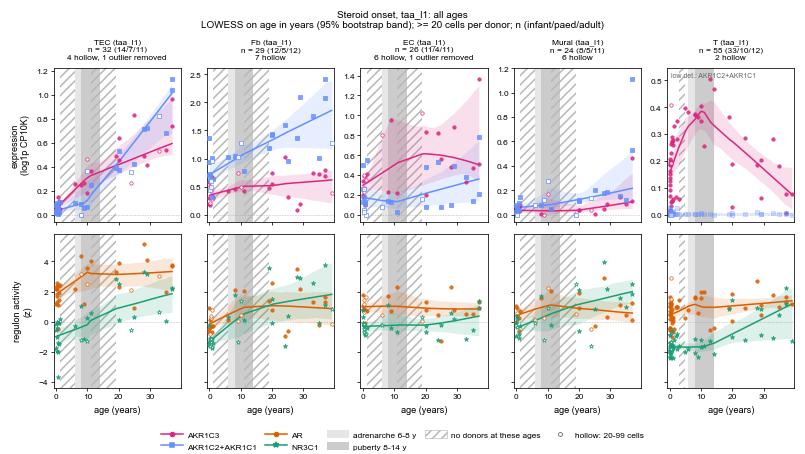

saved thyAgeing_steroidOnset_Fig1_taa_l1_upto20y.pdf  (183 x 102 mm)


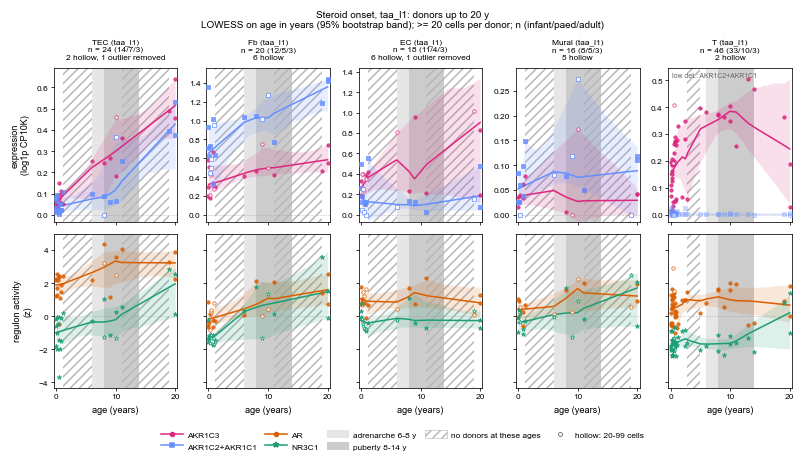

[2026-11-23 00:25:26] taa_l1 figures done


In [14]:
for window in WINDOWS:
    onset_figure('taa_l1', window)
log_step('taa_l1 figures done')


### 6b. `taa_l2_v2`: cTEC, mcTEC, mTEC, with the cortical programme


saved thyAgeing_steroidOnset_Fig2_taa_l2_v2_allAges.pdf  (120 x 136 mm)


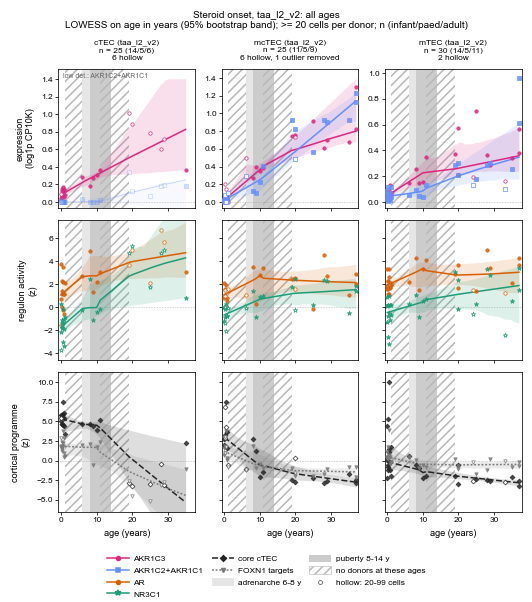

saved thyAgeing_steroidOnset_Fig2_taa_l2_v2_upto20y.pdf  (120 x 136 mm)


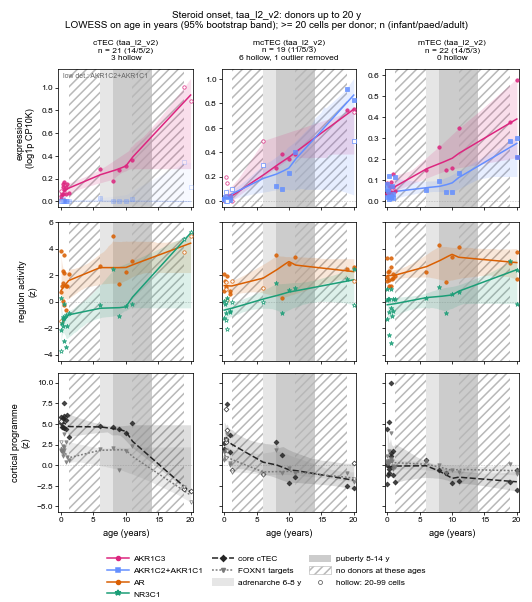

[2026-11-23 00:25:29] taa_l2_v2 figures done


In [15]:
for window in WINDOWS:
    onset_figure('taa_l2_v2', window)
log_step('taa_l2_v2 figures done')


## 7. The numbers: medians per age group

The median of every plotted trace in each age group, in the trace's own unit, after outlier removal,
with the differences from the infant median. For the enzymes a difference of log1p CP10K is roughly a
log fold change once expression is well above 1 CP10K. Near zero it is closer to a difference in CP10K,
so the CP10K medians are given too.


In [16]:
def age_medians(P, traces=None):
    """Median of every plotted trace (or of `traces` only) per age group of the donor table P, with the
    differences from the infant median; the enzymes also in CP10K."""
    rows = []
    for pop in POPS:
        d = P[P['population'] == pop]
        for tr in traces_for(pop):
            if traces is not None and tr not in traces:
                continue
            m = d.groupby('age_group')[tr].median().reindex(AGE_GROUPS)
            n = d.groupby('age_group')[tr].count().reindex(AGE_GROUPS).fillna(0).astype(int)
            enzyme = TRACES[tr]['kind'] == 'enzyme'
            row = {'population': pop, 'trace': tr, 'unit': 'log1p CP10K' if enzyme else 'z',
                   'low det.': (pop, tr) in LOW_DET, 'n infant/paed/adult': '/'.join(map(str, n)),
                   'infant': m['infant'], 'paed': m['paed'], 'adult': m['adult'],
                   'paed - infant': m['paed'] - m['infant'], 'adult - infant': m['adult'] - m['infant']}
            if enzyme:
                cp = d.groupby('age_group')[f'{tr} CP10K'].median().reindex(AGE_GROUPS)
                row.update({f'CP10K {g}': cp[g] for g in AGE_GROUPS})
            rows.append(row)
    return pd.DataFrame(rows)


MEDIANS = age_medians(PLOT)
display(MEDIANS.set_index(['population', 'trace']).round(3))


unit  low det. n infant/paed/adult  infant   paed  adult  paed - infant  adult - infant  CP10K infant  CP10K paed  CP10K adult
population trace                                                                                                                                               
TEC        AKR1C3         log1p CP10K     False             14/7/11   0.061  0.254  0.528          0.193           0.467         0.063       0.289        0.696
           AKR1C2+AKR1C1  log1p CP10K     False             14/7/11   0.022  0.091  0.680          0.069           0.659         0.022       0.095        0.974
           AR                       z     False             14/7/11   2.033  3.184  3.275          1.150           1.241           NaN         NaN          NaN
           NR3C1                    z     False             14/7/11  -0.773 -0.286  2.201          0.488           2.975           NaN         NaN          NaN
Fb         AKR1C3         log1p CP10K     False             12/5/12   0.305  0.466  0.619          0.160           0.313         0.357       0.593        0.861
           AKR1C2+AKR1C1  log1p CP10K     False             12/5/12   0.671  1.035  1.432          0.364           0.760         0.958       1.816        3.186
           AR                       z     False             12/5/12  -0.281  0.421  1.311          0.703           1.592           NaN         NaN          NaN
           NR3C1                    z     False             12/5/12  -1.343  0.320  1.322          1.663           2.666           NaN         NaN          NaN
EC         AKR1C3         log1p CP10K     False             11/4/11   0.335  0.517  0.563          0.182           0.228         0.398       0.748        0.757
           AKR1C2+AKR1C1  log1p CP10K     False             11/4/11   0.127  0.101  0.208         -0.026           0.081         0.135       0.107        0.231
           AR                       z     False             11/4/11   0.838  1.208  0.785          0.369          -0.054           NaN         NaN          NaN
           NR3C1                    z     False             11/4/11  -0.410 -0.319 -0.191          0.091           0.219           NaN         NaN          NaN
Mural      AKR1C3         log1p CP10K     False              8/5/11   0.034  0.051  0.050          0.016           0.015         0.035       0.052        0.051
           AKR1C2+AKR1C1  log1p CP10K     False              8/5/11   0.048  0.081  0.154          0.033           0.106         0.050       0.085        0.167
           AR                       z     False              8/5/11   0.477  1.579  0.528          1.102           0.051           NaN         NaN          NaN
           NR3C1                    z     False              8/5/11  -0.295 -0.071  1.862          0.225           2.157           NaN         NaN          NaN
T          AKR1C3         log1p CP10K     False            33/10/12   0.189  0.378  0.185          0.188          -0.005         0.209       0.459        0.203
           AKR1C2+AKR1C1  log1p CP10K      True            33/10/12   0.004  0.002  0.003         -0.002          -0.001         0.004       0.002        0.003
           AR                       z     False            33/10/12   0.678  1.170  1.157          0.492           0.479           NaN         NaN          NaN
           NR3C1                    z     False            33/10/12  -1.641 -1.722  0.619         -0.081           2.261           NaN         NaN          NaN
cTEC       AKR1C3         log1p CP10K     False              14/5/6   0.085  0.285  0.747          0.200           0.662         0.089       0.330        1.112
           AKR1C2+AKR1C1  log1p CP10K      True              14/5/6   0.000  0.005  0.185          0.005           0.185         0.000       0.005        0.203
           AR                       z     False              14/5/6   1.168  2.702  4.345          1.534           3.176           NaN         NaN          NaN
           NR3C1                 

## 8. The same figures, with AR and NR3C1 activity corrected for sequencing depth

Sections 6–7 plot every value as measured. Here the **AR and NR3C1 activity z** of every donor is corrected
for the depth of its pseudobulk and the figures of section 6 are redrawn. The covariates are notebook 06's
(section 7 there): `log10` library size and `log10` cells. **Enzyme expression and the cortical scores
are not corrected.** They are already per-10K-count measures, and their rows are the same as in section 6.

**Why notebook 06's regression is not reused as it stands.** Notebook 06 regresses z on depth across all
donors of a population, at all ages. That is harmless for a female-vs-male test inside one age group.
In an age-trend figure, though, it removes part of the age trend itself wherever depth changes with
age, and in these pseudobulks it does (first table below; median library sizes). Adult Fb pseudobulks
are ~10–20× deeper than the infant and child ones. Adult EC and Mural are ~3× deeper than infants and
~10–20× deeper than children. mcTEC pseudobulks deepen ~10× from infancy to adulthood, and adult cTEC are
~6× shallower than infant cTEC. In such a panel the all-ages slope is partly the age trend.

**What is done instead.** Per population × receptor, z is regressed on **age-group indicators**
(infant, paed, adult) plus `log10` library size and `log10` cells. With the age groups in the model the
depth slopes come only from donor-to-donor differences **within** an age group. Only the depth part of
the fit is removed:

    z_corrected = z − β_lib · (log10 lib − mean) − β_cells · (log10 cells − mean)

This is notebook 06's form (residual + mean), with the slope protected from the age trend. Take a panel
whose adults are deeper and whose deeper donors score higher within every age group: the adults come
down by what their extra depth predicts, and no further.

* Donors: exactly those of sections 6–7 (outliers removed by the section 5 rule on the measured values).
  One fit per population × receptor, on all ages, applied in both windows.
* Trend fits: the same LOWESS and the same bootstrap resamples (seeds) as section 6. Any difference
  between a figure and its `_depthCorrected` twin therefore comes from the correction.
* `p depth | age group`: the F test of the two depth terms added to the age-group model, i.e. whether there
  is a depth effect to remove. `r within age group`: the Pearson correlation of z with `log10` library size
  after centring both within age groups. `correction SD`: the spread of the subtracted depth term, in z.
* `… nb06-style`: the same difference of medians with notebook 06's all-ages slope, for comparison only.

**Caveats.** Library size and cells per pseudobulk are nearly collinear, so the two slopes cannot be
read separately; only their combined term is meaningful. In practice they come out near-equal and
opposite (`beta log10 lib` ≈ −`beta log10 cells`), so the term removed is in effect `log10` counts per
cell (sequencing depth per cell, but also cell size and RNA content). A depth slope within an age group can still be
partly biology (larger or better-preserved samples) or a within-group age trend (the adults span
19–70 y). The corrected figures are therefore a sensitivity analysis next to section 6, not a
replacement for it.


In [17]:
from scipy.stats import f as f_dist


def spearman(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    ok = np.isfinite(a) & np.isfinite(b)
    return float(spearmanr(a[ok], b[ok])[0]) if ok.sum() >= 4 else np.nan


def depth_fit(y, depth, groups=None):
    """Least squares of y on the depth covariates plus one intercept per age group (groups given: the slopes
    come from within-group variation only) or one common intercept (groups=None: notebook 06's regression).
    Returns the depth slopes, the residual sums of squares without and with the depth terms, and the number
    of intercepts."""
    base = (pd.get_dummies(pd.Series(groups)).to_numpy(float) if groups is not None
            else np.ones((len(y), 1)))
    X = np.column_stack([base, depth])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    b0, *_ = np.linalg.lstsq(base, y, rcond=None)
    rss1, rss0 = float(((y - X @ beta) ** 2).sum()), float(((y - base @ b0) ** 2).sum())
    return beta[base.shape[1]:], rss0, rss1, base.shape[1]


def within_r(y, x, groups):
    """Pearson r of y and x after centring both within each group."""
    s = pd.DataFrame({'y': y, 'x': x, 'g': groups})
    c = s[['y', 'x']] - s.groupby('g')[['y', 'x']].transform('mean')
    return float(np.corrcoef(c['y'], c['x'])[0, 1]) if (c.std() > 0).all() else np.nan


# ---- does depth change with age? (per population, the donors of the figures)
rows = []
for pop in POPS:
    P = PLOT[PLOT['population'] == pop]
    med = P.groupby('age_group')['log10_lib'].median().reindex(AGE_GROUPS)
    rows.append({'population': pop, 'donors': len(P), 'infant/paed/adult': age_mix(P),
                 'rho(log10 lib, age)': spearman(P['log10_lib'], P['age_years']),
                 'rho(log10 cells, age)': spearman(P['log10_cells'], P['age_years']),
                 **{f'median log10 lib {g}': med[g] for g in AGE_GROUPS}})
DEPTH_AGE = pd.DataFrame(rows).set_index('population')
print('Depth against age (Spearman over the donors of the figures; median log10 library size per age group):')
display(DEPTH_AGE.round(2))

# ---- the correction, per population x receptor
PLOT_D = PLOT.copy()          # the figure table, with DEPTH_TRACES depth-corrected
PLOT_P = PLOT.copy()          # the same with notebook 06's all-ages slope (comparison only)
rows = []
for pop in POPS:
    m = (PLOT['population'] == pop).to_numpy()
    P = PLOT[m]
    for tr in DEPTH_TRACES:
        y = P[tr].to_numpy(float)
        ok = np.isfinite(y)
        dep = P[DEPTH_COVS].to_numpy(float)
        grp = P['age_group'].to_numpy()
        beta, rss0, rss1, k = depth_fit(y[ok], dep[ok], grp[ok])
        beta_06, *_ = depth_fit(y[ok], dep[ok])
        df2 = int(ok.sum()) - k - len(DEPTH_COVS)
        F = ((rss0 - rss1) / len(DEPTH_COVS)) / (rss1 / df2) if df2 > 0 and rss1 > 0 else np.nan
        term, term_06 = (dep - dep[ok].mean(axis=0)) @ beta, (dep - dep[ok].mean(axis=0)) @ beta_06
        PLOT_D.loc[m, tr] = y - term
        PLOT_P.loc[m, tr] = y - term_06
        rows.append({'population': pop, 'trace': tr, 'donors': int(ok.sum()),
                     'r depth, all ages': float(np.corrcoef(y[ok], P['log10_lib'].to_numpy(float)[ok])[0, 1]),
                     'r depth, within age group': within_r(y[ok], P['log10_lib'].to_numpy(float)[ok], grp[ok]),
                     'p depth | age group': float(f_dist.sf(F, len(DEPTH_COVS), df2)) if np.isfinite(F) else np.nan,
                     'beta log10 lib': beta[0], 'beta log10 cells': beta[1],
                     'correction SD': float(np.std(term[ok], ddof=1)),
                     'rho corrected vs measured': spearman(y, PLOT_D.loc[m, tr])})


def med_diffs(P, pop, tr):
    md_ = P[P['population'] == pop].groupby('age_group')[tr].median().reindex(AGE_GROUPS)
    return md_['paed'] - md_['infant'], md_['adult'] - md_['infant']


DEPTH_QC = pd.DataFrame(rows)
for name, tbl in (('measured', PLOT), ('corrected', PLOT_D), ('nb06-style', PLOT_P)):
    dd = [med_diffs(tbl, p, t) for p, t in zip(DEPTH_QC['population'], DEPTH_QC['trace'])]
    DEPTH_QC[f'paed - infant, {name}'] = [a for a, _ in dd]
    DEPTH_QC[f'adult - infant, {name}'] = [b for _, b in dd]
print('Depth correction of AR and NR3C1 z (slopes within age groups), and the age-group median differences '
      'as measured, corrected, and with notebook 06\'s all-ages slope:')
display(DEPTH_QC.set_index(['trace', 'population']).round(3))
log_step('depth correction done')


Depth against age (Spearman over the donors of the figures; median log10 library size per age group):


,donors,infant/paed/adult,"rho(log10 lib, age)","rho(log10 cells, age)",median log10 lib infant,median log10 lib paed,median log10 lib adult
population,,,,,,,
TEC,32,14/7/11,0.15,0.18,6.80,6.87,7.21
Fb,29,12/5/12,0.41,0.49,6.04,6.31,7.29
EC,26,11/4/11,0.47,0.50,6.32,5.65,6.75
Mural,24,8/5/11,0.42,0.40,6.07,5.20,6.52
T,55,33/10/12,-0.19,-0.16,7.40,7.66,7.20
cTEC,25,14/5/6,-0.31,-0.44,6.24,6.16,5.45
mcTEC,25,11/5/9,0.51,0.51,5.93,6.39,6.92
mTEC,30,14/5/11,0.13,0.14,6.64,7.24,6.82


Depth correction of AR and NR3C1 z (slopes within age groups), and the age-group median differences as measured, corrected, and with notebook 06's all-ages slope:


,,donors,"r depth, all ages","r depth, within age group",p depth | age group,beta log10 lib,beta log10 cells,correction SD,rho corrected vs measured,"paed - infant, measured","adult - infant, measured","paed - infant, corrected","adult - infant, corrected","paed - infant, nb06-style","adult - infant, nb06-style"
trace,population,,,,,,,,,,,,,,
AR,TEC,32,0.149,0.209,0.153,1.733,-1.448,0.373,0.938,1.150,1.241,1.730,1.363,1.793,1.387
NR3C1,TEC,32,0.300,0.383,0.060,1.777,-1.164,0.514,0.888,0.488,2.975,1.108,2.767,0.958,2.281
AR,Fb,29,0.444,0.363,0.173,0.682,-0.293,0.434,0.922,0.703,1.592,1.201,1.192,1.388,1.110
NR3C1,Fb,29,0.576,0.430,0.040,1.578,-1.190,0.624,0.909,1.663,2.666,1.508,2.370,1.407,1.874
AR,EC,26,-0.221,-0.078,0.316,0.680,-0.988,0.249,0.887,0.369,-0.054,0.295,0.048,0.235,0.133
NR3C1,EC,26,0.256,0.256,0.171,0.944,-0.901,0.277,0.867,0.091,0.219,0.149,-0.041,0.138,-0.023
AR,Mural,24,0.085,0.194,0.220,1.444,-1.542,0.320,0.917,1.102,0.051,0.930,0.442,0.972,0.498
NR3C1,Mural,24,0.433,0.340,0.088,2.277,-2.168,0.572,0.908,0.225,2.157,0.630,1.529,0.864,1.273
AR,T,55,-0.044,-0.016,0.145,1.208,-1.396,0.226,0.967,0.492,0.479,0.380,0.542,0.361,0.507


[2026-11-23 00:25:29] depth correction done


### 8a. `taa_l1` and 8b. `taa_l2_v2`, AR and NR3C1 activity depth-corrected

Same layout, donors, fits and bootstrap seeds as section 6. Only the receptor row (`AR`, `NR3C1`,
labelled *depth-corr.*) differs; its y axis is again shared across the cell types of a figure.


saved thyAgeing_steroidOnset_Fig1_taa_l1_allAges_depthCorrected.pdf  (183 x 102 mm)


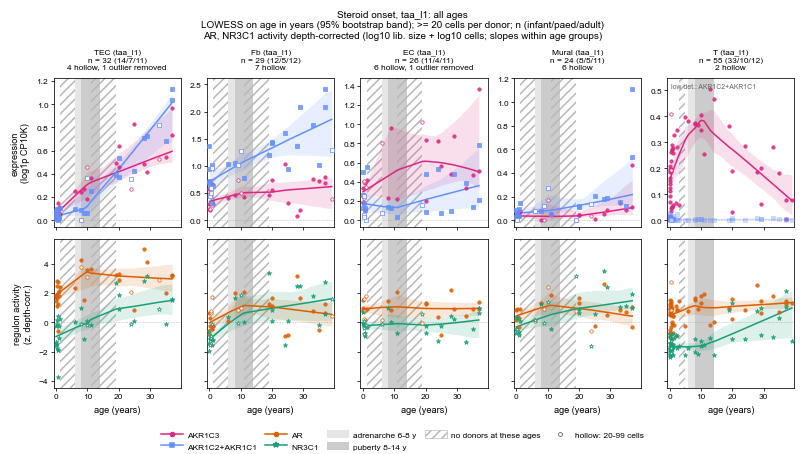

saved thyAgeing_steroidOnset_Fig1_taa_l1_upto20y_depthCorrected.pdf  (183 x 102 mm)


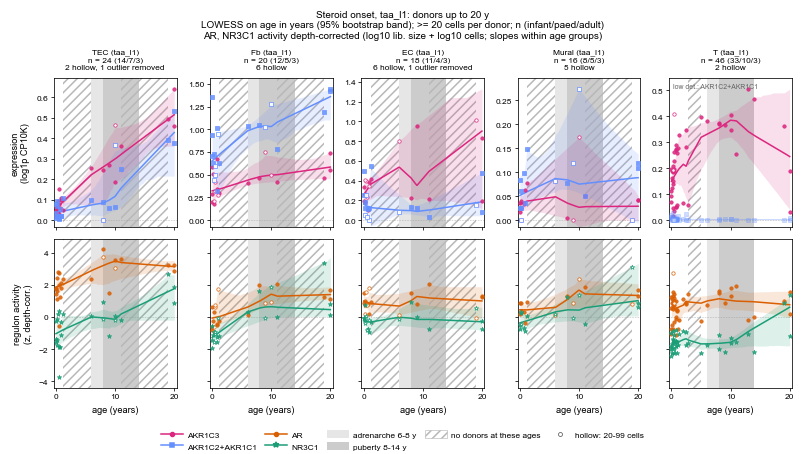

saved thyAgeing_steroidOnset_Fig2_taa_l2_v2_allAges_depthCorrected.pdf  (120 x 136 mm)


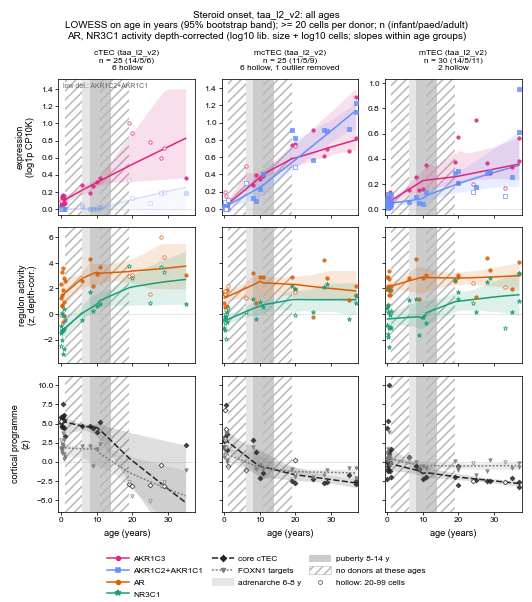

saved thyAgeing_steroidOnset_Fig2_taa_l2_v2_upto20y_depthCorrected.pdf  (120 x 136 mm)


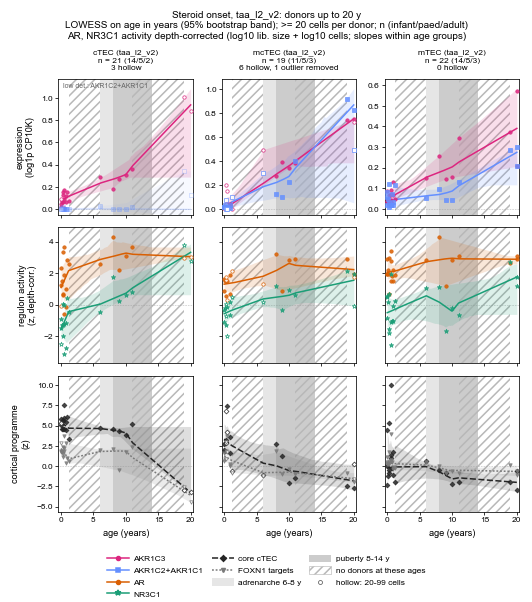

[2026-11-23 00:26:08] depth-corrected figures done


In [18]:
FITS_D, FIT_TBL_D = fit_all(PLOT_D, traces=DEPTH_TRACES)
FITS_D = {**FITS, **FITS_D}            # the uncorrected traces keep their section-6 fits
for level in LEVELS:
    for window in WINDOWS:
        onset_figure(level, window, P=PLOT_D, fits=FITS_D, tag='depthCorrected')
log_step('depth-corrected figures done')


### 8c. Medians per age group, depth-corrected

As section 7, for AR and NR3C1 after the depth correction.


In [19]:
MEDIANS_D = age_medians(PLOT_D, traces=DEPTH_TRACES)
cmp = MEDIANS.merge(MEDIANS_D, on=['population', 'trace'], suffixes=('', ', corrected'))
display(cmp[['trace', 'population', 'n infant/paed/adult', 'infant', 'paed', 'adult', 'infant, corrected',
             'paed, corrected', 'adult, corrected']].set_index(['trace', 'population']).round(2))


,,n infant/paed/adult,infant,paed,adult,"infant, corrected","paed, corrected","adult, corrected"
trace,population,,,,,,,
AR,TEC,14/7/11,2.03,3.18,3.27,1.81,3.54,3.18
NR3C1,TEC,14/7/11,-0.77,-0.29,2.20,-1.23,-0.12,1.54
AR,Fb,12/5/12,-0.28,0.42,1.31,-0.25,0.95,0.94
NR3C1,Fb,12/5/12,-1.34,0.32,1.32,-1.16,0.34,1.21
AR,EC,11/4/11,0.84,1.21,0.78,0.85,1.14,0.90
NR3C1,EC,11/4/11,-0.41,-0.32,-0.19,-0.21,-0.06,-0.25
AR,Mural,8/5/11,0.48,1.58,0.53,0.36,1.29,0.80
NR3C1,Mural,8/5/11,-0.30,-0.07,1.86,-0.47,0.16,1.06
AR,T,33/10/12,0.68,1.17,1.16,0.74,1.12,1.28


## 9. Summary (run of 2026-11-12, 1,000 permutations; section 8 added 2026-11-23)

**Sampling first.** Every epithelial and stromal panel has its children at **6–11 y** (4–7 donors) and no
donor between ~1.2 and 6 y or between 11 and 19 y (hatched). "Up by childhood" therefore means "risen
somewhere between infancy and 6–11 y": the start of a rise **cannot** be placed before, at or after
adrenarche onset inside the 1.2–6 y gap. T cells are the only panel with donors at 2–5 y and 13–14 y.
Three low-cell donors were removed as strong outliers (section 5): **Thy13** (29 y, Li2024) in TEC and
mcTEC (AKR1C2+AKR1C1 ~6 CP10K from 28–34 cells, ~3× the next donor), and **baut_paed1** (6 d) in EC
(AKR1C2+AKR1C1 from 41 cells). A70 (37 y) is the highest-AKR1C donor in several compartments, but its
pseudobulks are large, so it is kept.

Medians per age group (infant → child → adult), section 7:

* **Androgen-activating AKR1C3 rises by childhood in every epithelial panel.** CP10K: TEC 0.06 →
  0.29 → 0.70, cTEC 0.09 → 0.33 → 1.11, mcTEC 0.04 → 0.47 → 1.10, mTEC 0.05 → 0.17 → 0.44. It also rises
  in Fb (0.36 → 0.59 → 0.86) and EC (0.40 → 0.75 → 0.76, already at the adult level by childhood). In T
  cells it peaks in childhood and falls back in adults (0.21 → 0.46 → 0.20).
* **The inactivating AKR1C2+AKR1C1 rise is mostly adult on the log1p CP10K axis.** In TEC it reaches
  0.10 of 0.97 CP10K by childhood, and in mTEC 0.06 of 0.33. **This is partly a scale effect.** As a fold
  change from infancy the two arms have moved alike by childhood in TEC (×4.3 vs ×4.6 for AKR1C3); the
  inactivating arm then rises much further in adults (×44 vs ×11). The CP10K medians are in section 7.
  mcTEC is the exception: both arms are up >10-fold by childhood. Fb has the highest AKR1C2+AKR1C1 of any
  compartment (0.96 → 1.82 → 3.19). It is low-detection in cTEC and T.
* **AR activity reaches its adult level by childhood in epithelium.** z: TEC 2.0 → 3.2 → 3.3, mcTEC
  1.1 → 2.8 → 2.4, mTEC 1.9 → 3.3 → 2.9. In cTEC it keeps rising into adulthood (1.2 → 2.7 → 4.3). In Fb it
  rises gradually (−0.3 → 0.4 → 1.3). EC is flat, and T rises a little (0.7 → 1.2 → 1.2).
* **Per child donor, AKR1C3 comes before AR.** The one 6 y donor (Z13) already has 3–18 times the
  infant AKR1C3 median (TEC 0.29 vs 0.06 CP10K, cTEC 0.33 vs 0.09, mcTEC 0.64 vs 0.04, mTEC 0.16 vs
  0.05). Its AR z is still at the infant level in TEC, mcTEC and mTEC (2.2, 1.1, 2.2 vs infant medians
  2.0, 1.1, 1.9). The 8–11 y Thymus_ageing donors sit at AR z 2.2–4.9. The one child from another study
  (Notarangelo 2024, 9 y) is low in every TEC panel (0.3–1.5), so part of the childhood AR step may be a
  study effect.
* **NR3C1 activity rises later than AR.** z: TEC −0.8 → −0.3 → 2.2 and cTEC −1.5 → −0.2 → 4.8, i.e. most of
  the rise comes after childhood. Mural (−0.3 → −0.1 → 1.9) and T (−1.6 → −1.7 → 0.6) are the same. In
  mcTEC (−0.7 → 0.9 → 1.7) and Fb (−1.3 → 0.3 → 1.3) about two-thirds of the rise is there by childhood.
* **The cortical programme.** In **cTEC**, core cTEC (5.4 → 4.6 → −3.0) and FOXN1-target z (1.8 → 2.0 → −2.9)
  are **maintained through childhood**, while AR activity and AKR1C3 are already up. The fall comes
  after 11 y. Note that cTEC has 6 adult donors, mostly 20–99 cells. In **mcTEC** the core score falls
  by childhood (2.9 → −1.1 → −2.5), together with the AKR1C rise. In mTEC it drifts down.
* **Depth (section 8; AR and NR3C1 only).** Depth tracks age in several panels: the Spearman ρ of `log10`
  library size with age is 0.41–0.51 in Fb, EC, Mural and mcTEC and −0.31 in cTEC. The slope is therefore
  estimated within age groups. A depth effect within age groups is clear in 4 of 16 receptor × population
  fits (F test *p* < 0.05: AR in mTEC; NR3C1 in cTEC, mTEC and Fb). In every fit the library-size and
  cell-number slopes are near-equal and opposite, so what is removed is in effect **`log10` counts per
  cell**: donors with more counts per cell score higher. Corrected and measured z agree per donor at
  Spearman 0.83–0.98. **The timing conclusions hold.** AR is at its adult level by childhood in TEC
  (corrected 1.8 → 3.5 → 3.2), mcTEC (1.5 → 2.9 → 2.0) and mTEC (1.9 → 2.8 → 2.9), and now also in Fb
  (−0.3 → 0.9 → 0.9). cTEC's continued adult AR rise disappears (1.4 → 3.1 → 3.0): its 6 adult donors,
  mostly 20–99 cells, have ~1.8× the infants' counts per cell. NR3C1 still rises mostly after childhood,
  with smaller adult rises (adult − infant: TEC 3.0 → 2.8, cTEC 6.2 → 4.3, Mural 2.2 → 1.5, mcTEC
  2.5 → 1.8), and later in mTEC (−0.5 → −0.2 → 1.2). Per child donor: Z13 (6 y) stays near the infant AR
  level in TEC and mcTEC (2.4 and 1.3 vs corrected infant medians 1.8 and 1.5) but not in mTEC (2.8 vs
  1.9). The Notarangelo 9 y child is still the lowest child in every TEC panel. Notebook 06's all-ages
  slope would have removed much of the cTEC rises (adult − infant: AR 3.2 → 1.2, NR3C1 6.2 → 1.9), i.e.
  part of the age trend itself.

**What this supports.** AKR1C3 is up in thymic epithelium by the youngest child donor (6 y), i.e. its
rise starts before or at the onset of adrenarche, somewhere in the 1.2–6 y gap. AR target activity is up
from 8 y in the Thymus_ageing children, so the activating enzyme appears to lead AR activity. NR3C1
activity and the bulk of the inactivating arm follow later, around or after puberty. In cTEC the loss
of cortical identity comes after the AR rise rather than with it. With AR and NR3C1 corrected for depth
(section 8) the timing is the same; the adult rises in cTEC and mcTEC shrink, so their size rests partly
on counts per cell. Every timing statement here rests on 4–7
child donors, one of them 6 y old, and most from one study (Thymus_ageing; Notarangelo 2024 adds the
9 y donor). Age and study are therefore partly confounded, and co-movement across donors is not
coupling.


## 10. Outputs

`results/` (prefix `thyAgeing_steroidOnset_`):

* `donorValues.csv` — every analysed donor × cell type: metadata, the enzymes (counts, CP10K, log1p
  CP10K), the activity z of AR, NR3C1 and the cortical scores, and `outlier_removed`;
* `outliers.csv` — every extreme value of section 5, removed or kept; `enzymeDetection.csv` — section 4;
* `trendFits.csv.gz` — the LOWESS fit and band of every trace × cell type × window on its age grid;
* `medians.csv` — section 7;
* `activity_perDonor.csv` — the score cache (`score`, `null_mean`, `null_sd`, `z`);
* section 8: `depthByAge.csv` (depth against age per population), `depthCorrection.csv` (per population ×
  receptor: depth slopes, F test, the age-group median differences measured / corrected / nb06-style),
  `donorValues_depthCorrected.csv` (metadata + measured and depth-corrected AR / NR3C1 z of every
  plotted donor), `trendFits_depthCorrected.csv.gz`, `medians_depthCorrected.csv`.

`figures/`: `Fig1_taa_l1_{allAges,upto20y}` and `Fig2_taa_l2_v2_{allAges,upto20y}`, and their
`_depthCorrected` twins (section 8) (PDF, sized in mm).


In [20]:
VALS.to_csv(f'{RESULTS}/{PREFIX}_donorValues.csv', index=False)
OUTLIERS.to_csv(f'{RESULTS}/{PREFIX}_outliers.csv', index=False)
DET.to_csv(f'{RESULTS}/{PREFIX}_enzymeDetection.csv', index=False)
FIT_TBL.to_csv(f'{RESULTS}/{PREFIX}_trendFits.csv.gz', index=False)
MEDIANS.to_csv(f'{RESULTS}/{PREFIX}_medians.csv', index=False)
DEPTH_AGE.reset_index().to_csv(f'{RESULTS}/{PREFIX}_depthByAge.csv', index=False)
DEPTH_QC.to_csv(f'{RESULTS}/{PREFIX}_depthCorrection.csv', index=False)
(PLOT[META + DEPTH_TRACES]
 .merge(PLOT_D[['population', 'donor'] + DEPTH_TRACES], on=['population', 'donor'], suffixes=('', ' depthCorrected'),
        validate='one_to_one')
 .to_csv(f'{RESULTS}/{PREFIX}_donorValues_depthCorrected.csv', index=False))
FIT_TBL_D.to_csv(f'{RESULTS}/{PREFIX}_trendFits_depthCorrected.csv.gz', index=False)
MEDIANS_D.to_csv(f'{RESULTS}/{PREFIX}_medians_depthCorrected.csv', index=False)
for folder in (RESULTS, FIGURES):
    print(folder)
    for f in sorted(x for x in os.listdir(folder) if x.startswith(PREFIX)):
        print('   ', f)
log_step('=== notebook done')


/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/notebooks/hormone2cell/_builders/../final_versions/github/results
    thyAgeing_steroidOnset_activity_perDonor.csv
    thyAgeing_steroidOnset_depthByAge.csv
    thyAgeing_steroidOnset_depthCorrection.csv
    thyAgeing_steroidOnset_donorValues.csv
    thyAgeing_steroidOnset_donorValues_depthCorrected.csv
    thyAgeing_steroidOnset_enzymeDetection.csv
    thyAgeing_steroidOnset_medians.csv
    thyAgeing_steroidOnset_medians_depthCorrected.csv
    thyAgeing_steroidOnset_outliers.csv
    thyAgeing_steroidOnset_progress.log
    thyAgeing_steroidOnset_trendFits.csv.gz
    thyAgeing_steroidOnset_trendFits_depthCorrected.csv.gz
/nfs/team205/vk8/projects/thymus_ageing_atlas/General_analysis/notebooks/hormone2cell/_builders/../final_versions/github/figures
    thyAgeing_steroidOnset_Fig1_taa_l1_allAges.pdf
    thyAgeing_steroidOnset_Fig1_taa_l1_allAges_depthCorrected.pdf
    thyAgeing_steroidOnset_Fig1_taa_l1_upto20y.pdf
    thyAgein